In [1]:
import os
from PIL import Image

# 指定目标目录
dir_path = "/public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06"

# 获取目录中所有可能的图像文件
image_files = [
    f for f in os.listdir(dir_path) 
    if f.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff'))
]

# 遍历图像文件并输出其宽高
for image_file in image_files:
    image_path = os.path.join(dir_path, image_file)
    with Image.open(image_path) as img:
        width, height = img.size
        print(f"File: {image_file} - Width: {width}, Height: {height}")


File: DJI_20230526075444_0868_L06_1.png - Width: 2457, Height: 2377
File: DJI_20230526075445_0869_L06_0.png - Width: 2463, Height: 4534
File: DJI_20230526075446_0870_L06_0.png - Width: 2461, Height: 5460
File: DJI_20230526075447_0871_L06_0.png - Width: 2458, Height: 5460
File: DJI_20230526075448_0872_L06_0.png - Width: 2460, Height: 5460
File: DJI_20230526075449_0873_L06_0.png - Width: 2466, Height: 5460
File: DJI_20230526075450_0874_L06_0.png - Width: 2468, Height: 3558
File: DJI_20230526075451_0875_L06_1.png - Width: 2466, Height: 1614


所有图像的最小宽度: 2457, 最小高度: 1614


/tmp/ipykernel_1151064/1517331947.py:65: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1151064/1517331947.py:65: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1151064/1517331947.py:65: UserWarning: Glyph 35009 (\N{CJK UNIFIED IDEOGRAPH-88C1}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1151064/1517331947.py:65: UserWarning: Glyph 21098 (\N{CJK UNIFIED IDEOGRAPH-526A}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1151064/1517331947.py:65: UserWarning: Glyph 21306 (\N{CJK UNIFIED IDEOGRAPH-533A}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1151064/1517331947.py:65: UserWarning: Glyph 22495 (\N{CJK UNIFIED IDEOGRAPH-57DF}) missing from current font.
  plt.tight_layout()
/public/home/zncui/anaconda3/envs/mmdetection/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning:

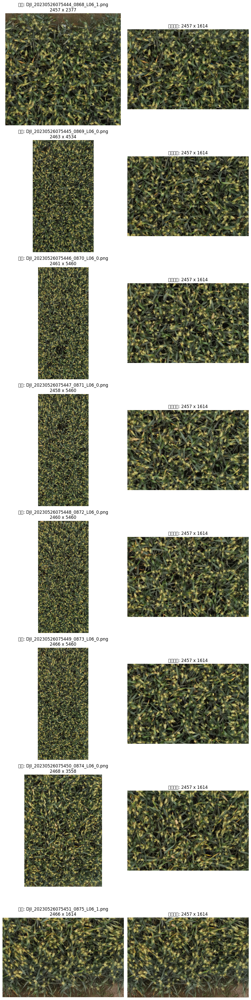

In [2]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# 目标目录路径
dir_path = "/public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06"

# 支持的图像格式
image_extensions = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')

# 获取目录中所有图像文件
image_files = [f for f in os.listdir(dir_path) if f.lower().endswith(image_extensions)]

if not image_files:
    print("该目录下没有找到图像文件。")
else:
    # 遍历所有图像获取最小宽度和最小高度
    min_width = float('inf')
    min_height = float('inf')
    
    for f in image_files:
        image_path = os.path.join(dir_path, f)
        with Image.open(image_path) as img:
            width, height = img.size
            if width < min_width:
                min_width = width
            if height < min_height:
                min_height = height
                
    print(f"所有图像的最小宽度: {min_width}, 最小高度: {min_height}")
    
    # 定义从图像中心裁剪固定区域的函数
    def crop_center(img, crop_width, crop_height):
        width, height = img.size
        left = (width - crop_width) // 2
        top = (height - crop_height) // 2
        right = left + crop_width
        bottom = top + crop_height
        return img.crop((left, top, right, bottom))
    
    # 根据图像数量创建图像展示
    num_images = len(image_files)
    fig, axs = plt.subplots(nrows=num_images, ncols=2, figsize=(10, 5 * num_images))
    
    # 如果只有一张图，axs 可能不是二维数组，这里做个统一处理
    if num_images == 1:
        axs = [axs]
    
    # 遍历每张图像显示原图与裁剪图
    for idx, f in enumerate(image_files):
        image_path = os.path.join(dir_path, f)
        img = Image.open(image_path)
        cropped_img = crop_center(img, min_width, min_height)
        
        # 左侧显示原图
        axs[idx][0].imshow(img)
        axs[idx][0].set_title(f"原图: {f}\n{img.size[0]} x {img.size[1]}")
        axs[idx][0].axis('off')
        
        # 右侧显示裁剪图
        axs[idx][1].imshow(cropped_img)
        axs[idx][1].set_title(f"裁剪区域: {min_width} x {min_height}")
        axs[idx][1].axis('off')
    
    plt.tight_layout()
    plt.show()


所有图像的最小宽度: 2457, 最小高度: 1614


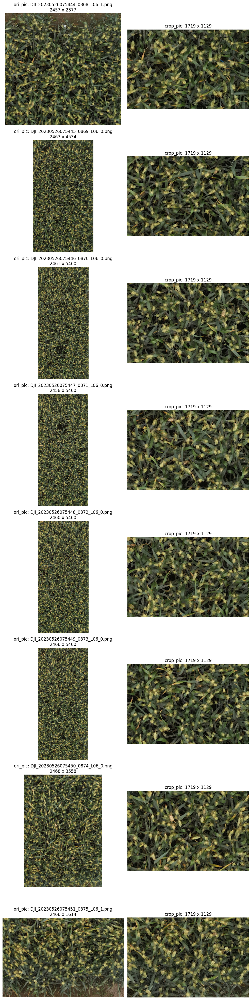

In [4]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# 目标目录路径
dir_path = "/public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06"

# 支持的图像格式
image_extensions = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')

# 获取目录中所有图像文件
image_files = [f for f in os.listdir(dir_path) if f.lower().endswith(image_extensions)]

if not image_files:
    print("该目录下没有找到图像文件。")
else:
    # 遍历所有图像获取最小宽度和最小高度
    min_width = float('inf')
    min_height = float('inf')
    
    for f in image_files:
        image_path = os.path.join(dir_path, f)
        with Image.open(image_path) as img:
            width, height = img.size
            min_width = min(min_width, width)
            min_height = min(min_height, height)
                
    print(f"所有图像的最小宽度: {min_width}, 最小高度: {min_height}")
    
    # 设置缩放因子 r（例如 1 表示不缩放，可以根据需要调整该值）
    r = 0.7
    crop_width = int(min_width * r)
    crop_height = int(min_height * r)
    
    # 定义从图像中心裁剪固定区域的函数
    def crop_center(img, crop_width, crop_height):
        width, height = img.size
        left = (width - crop_width) // 2
        top = (height - crop_height) // 2
        right = left + crop_width
        bottom = top + crop_height
        return img.crop((left, top, right, bottom))
    
    # 根据图像数量创建展示窗口
    num_images = len(image_files)
    fig, axs = plt.subplots(nrows=num_images, ncols=2, figsize=(10, 5 * num_images))
    
    # 如果只有一张图，确保 axs 为二维列表
    if num_images == 1:
        axs = [axs]
    
    # 遍历每张图像，左侧显示原图，右侧显示裁剪图
    for idx, f in enumerate(image_files):
        image_path = os.path.join(dir_path, f)
        img = Image.open(image_path)
        cropped_img = crop_center(img, crop_width, crop_height)
        
        # 左侧显示原图
        axs[idx][0].imshow(img)
        axs[idx][0].set_title(f"ori_pic: {f}\n{img.size[0]} x {img.size[1]}")
        axs[idx][0].axis('off')
        
        # 右侧显示裁剪图
        axs[idx][1].imshow(cropped_img)
        axs[idx][1].set_title(f"crop_pic: {crop_width} x {crop_height}")
        axs[idx][1].axis('off')
    
    plt.tight_layout()
    plt.show()


所有图像的最小宽度: 2457, 最小高度: 1614


/tmp/ipykernel_1274192/1609803109.py:119: UserWarning: Glyph 23610 (\N{CJK UNIFIED IDEOGRAPH-5C3A}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1274192/1609803109.py:119: UserWarning: Glyph 23544 (\N{CJK UNIFIED IDEOGRAPH-5BF8}) missing from current font.
  plt.tight_layout()
/public/home/zncui/anaconda3/envs/mmdetection/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 23610 (\N{CJK UNIFIED IDEOGRAPH-5C3A}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/public/home/zncui/anaconda3/envs/mmdetection/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 23544 (\N{CJK UNIFIED IDEOGRAPH-5BF8}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


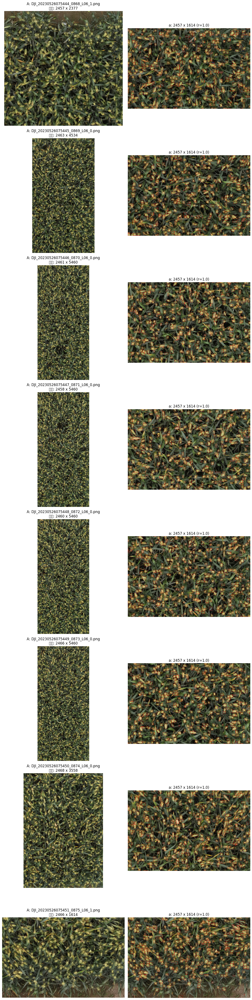

In [1]:
import os
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# 图片与标签文件目录
img_dir = "/public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06"
label_dir = "/public/home/zncui/pycharm_project/mmdetection/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06/results"

# 支持的图像文件格式
extensions = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')

# 获取目录中所有图像文件
image_files = [f for f in os.listdir(img_dir) if f.lower().endswith(extensions)]
if not image_files:
    print("该目录下没有找到图像文件。")
else:
    # 遍历所有图像获取最小宽度和最小高度
    min_width = float('inf')
    min_height = float('inf')
    
    for f in image_files:
        img_path = os.path.join(img_dir, f)
        with Image.open(img_path) as img:
            w, h = img.size
            min_width = min(min_width, w)
            min_height = min(min_height, h)
    
    print(f"所有图像的最小宽度: {min_width}, 最小高度: {min_height}")
    
    # 缩放因子 r，默认 1
    r = 1.0
    crop_width = int(min_width * r)
    crop_height = int(min_height * r)
    
    # 定义从中心裁剪图像的函数，返回裁剪后的图像以及裁剪区域左上角相对于原图的位置
    def crop_center(img, crop_width, crop_height):
        w, h = img.size
        left = (w - crop_width) // 2
        top = (h - crop_height) // 2
        right = left + crop_width
        bottom = top + crop_height
        cropped = img.crop((left, top, right, bottom))
        return cropped, left, top
    
    # 根据图片数量创建 Matplotlib 展示窗口，左右两列
    num_images = len(image_files)
    fig, axs = plt.subplots(nrows=num_images, ncols=2, figsize=(12, 6 * num_images))
    if num_images == 1:
        axs = [axs]
    
    # 遍历每张图片
    for i, f in enumerate(image_files):
        img_path = os.path.join(img_dir, f)
        # 对应标签文件，假设文件名相同，仅扩展名不同
        label_path = os.path.join(label_dir, os.path.splitext(f)[0] + ".txt")
        
        # 打开原图
        orig_img = Image.open(img_path)
        
        # 裁剪图像（从中心区域裁剪）
        cropped_img, crop_left, crop_top = crop_center(orig_img, crop_width, crop_height)
        
        # 复制裁剪图用于绘制框
        draw_img = cropped_img.copy()
        draw = ImageDraw.Draw(draw_img)
        
        # 如果标签文件存在，则读取标签并绘制框
        if os.path.exists(label_path):
            with open(label_path, 'r') as fp:
                lines = fp.readlines()
            for line in lines:
                line = line.strip()
                if not line:
                    continue
                # 标签格式为 "x,y,w,h"
                parts = line.split(',')
                if len(parts) != 4:
                    continue
                try:
                    x = float(parts[0])
                    y = float(parts[1])
                    box_w = float(parts[2])
                    box_h = float(parts[3])
                except Exception as e:
                    continue
                
                # 框在原图中的坐标
                box_left = x
                box_top = y
                box_right = x + box_w
                box_bottom = y + box_h
                
                # 转换到裁剪图坐标（裁剪图坐标 = 原图坐标 - 裁剪区域左上角偏移量）
                new_left = box_left - crop_left
                new_top = box_top - crop_top
                new_right = box_right - crop_left
                new_bottom = box_bottom - crop_top
                
                # 若框部分在裁剪区域外，则取交集，保证裁剪区域边缘的目标也保存
                new_left = max(new_left, 0)
                new_top = max(new_top, 0)
                new_right = min(new_right, crop_width)
                new_bottom = min(new_bottom, crop_height)
                
                # 若计算后框区域有效，则绘制
                if new_left < new_right and new_top < new_bottom:
                    draw.rectangle([new_left, new_top, new_right, new_bottom], outline="red", width=2)
        
        # 左侧显示原图，标注尺寸
        axs[i][0].imshow(orig_img)
        axs[i][0].set_title(f"A: {f}\n尺寸: {orig_img.size[0]} x {orig_img.size[1]}")
        axs[i][0].axis('off')
        
        # 右侧显示裁剪图（带框），标注裁剪区域尺寸
        axs[i][1].imshow(draw_img)
        axs[i][1].set_title(f"a: {crop_width} x {crop_height} (r={r})")
        axs[i][1].axis('off')
    
    plt.tight_layout()
    plt.show()


Minimum width among all images: 2457, Minimum height: 1614


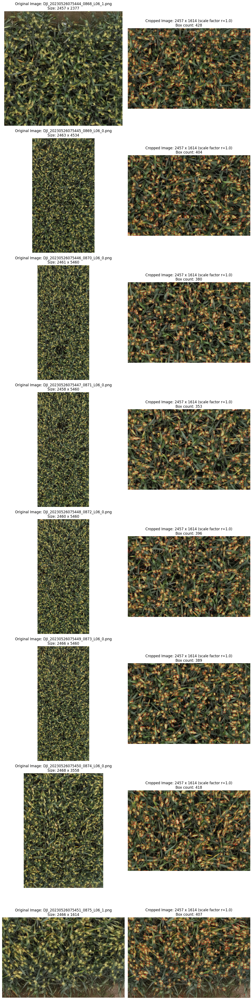

In [2]:
import os
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# Directories for images and labels
img_dir = "/public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06"
label_dir = "/public/home/zncui/pycharm_project/mmdetection/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06/results"

# Supported image file extensions
extensions = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')

# List all image files in the directory
image_files = [f for f in os.listdir(img_dir) if f.lower().endswith(extensions)]
if not image_files:
    print("No image files found in the directory.")
else:
    # Calculate the minimum width and height among all images
    min_width = float('inf')
    min_height = float('inf')
    
    for f in image_files:
        img_path = os.path.join(img_dir, f)
        with Image.open(img_path) as img:
            w, h = img.size
            min_width = min(min_width, w)
            min_height = min(min_height, h)
    
    print(f"Minimum width among all images: {min_width}, Minimum height: {min_height}")
    
    # Scale factor r, default is 1
    r = 1.0
    crop_width = int(min_width * r)
    crop_height = int(min_height * r)
    
    # Function to crop the image from the center.
    # Returns the cropped image and the (left, top) coordinates of the crop region in the original image.
    def crop_center(img, crop_width, crop_height):
        w, h = img.size
        left = (w - crop_width) // 2
        top = (h - crop_height) // 2
        right = left + crop_width
        bottom = top + crop_height
        cropped = img.crop((left, top, right, bottom))
        return cropped, left, top
    
    # Set up matplotlib to display images with two columns per row (Original and Cropped with boxes)
    num_images = len(image_files)
    fig, axs = plt.subplots(nrows=num_images, ncols=2, figsize=(12, 6 * num_images))
    if num_images == 1:
        axs = [axs]
    
    # Process each image
    for i, f in enumerate(image_files):
        img_path = os.path.join(img_dir, f)
        # Corresponding label file, assuming the same base name with .txt extension
        label_path = os.path.join(label_dir, os.path.splitext(f)[0] + ".txt")
        
        # Open the original image
        orig_img = Image.open(img_path)
        
        # Crop the image from the center
        cropped_img, crop_left, crop_top = crop_center(orig_img, crop_width, crop_height)
        
        # Create a copy of the cropped image for drawing bounding boxes
        draw_img = cropped_img.copy()
        draw = ImageDraw.Draw(draw_img)
        
        # Initialize the count of boxes for this cropped image
        box_count = 0
        
        # If the label file exists, read the labels and draw the boxes
        if os.path.exists(label_path):
            with open(label_path, 'r') as fp:
                lines = fp.readlines()
            for line in lines:
                line = line.strip()
                if not line:
                    continue
                # Label format: "x,y,w,h"
                parts = line.split(',')
                if len(parts) != 4:
                    continue
                try:
                    x = float(parts[0])
                    y = float(parts[1])
                    box_w = float(parts[2])
                    box_h = float(parts[3])
                except Exception as e:
                    continue
                
                # Original bounding box coordinates in the image
                box_left = x
                box_top = y
                box_right = x + box_w
                box_bottom = y + box_h
                
                # Convert to the cropped image's coordinate system by subtracting the crop offset
                new_left = box_left - crop_left
                new_top = box_top - crop_top
                new_right = box_right - crop_left
                new_bottom = box_bottom - crop_top
                
                # Clip the box coordinates to the crop boundaries (to include edge boxes)
                new_left = max(new_left, 0)
                new_top = max(new_top, 0)
                new_right = min(new_right, crop_width)
                new_bottom = min(new_bottom, crop_height)
                
                # If the adjusted box is valid, draw it and count it
                if new_left < new_right and new_top < new_bottom:
                    draw.rectangle([new_left, new_top, new_right, new_bottom], outline="red", width=2)
                    box_count += 1
        
        # Left column: display the original image with its size
        axs[i][0].imshow(orig_img)
        axs[i][0].set_title(f"Original Image: {f}\nSize: {orig_img.size[0]} x {orig_img.size[1]}")
        axs[i][0].axis('off')
        
        # Right column: display the cropped image with bounding boxes and box count
        axs[i][1].imshow(draw_img)
        axs[i][1].set_title(f"Cropped Image: {crop_width} x {crop_height} (scale factor r={r})\nBox count: {box_count}")
        axs[i][1].axis('off')
    
    plt.tight_layout()
    plt.show()


Minimum width among all images: 2457, Minimum height: 1614


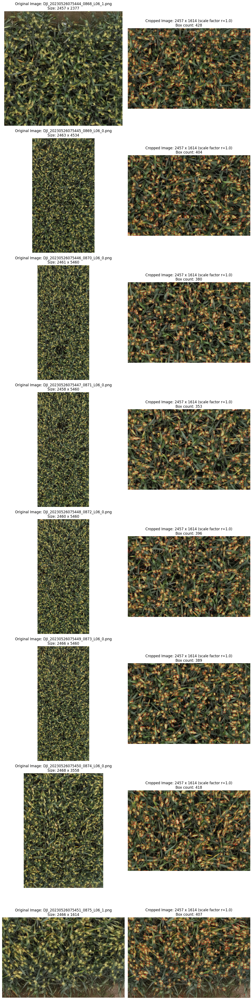

In [4]:
import os
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import pandas as pd

# Directories for images, original labels, and output results
img_dir = "/public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06"
label_dir = "/public/home/zncui/pycharm_project/mmdetection/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06/results"
output_dir = "/public/home/zncui/pycharm_project/mmdetection/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06/results2"

# Create the output directory if it does not exist
os.makedirs(output_dir, exist_ok=True)

# Supported image file extensions
extensions = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')

# List all image files in the image directory
image_files = [f for f in os.listdir(img_dir) if f.lower().endswith(extensions)]
if not image_files:
    print("No image files found in the directory.")
else:
    # Calculate the minimum width and height among all images
    min_width = float('inf')
    min_height = float('inf')
    
    for f in image_files:
        img_path = os.path.join(img_dir, f)
        with Image.open(img_path) as img:
            w, h = img.size
            min_width = min(min_width, w)
            min_height = min(min_height, h)
    
    print(f"Minimum width among all images: {min_width}, Minimum height: {min_height}")
    
    # Scale factor r (default is 1)
    r = 1.0
    crop_width = int(min_width * r)
    crop_height = int(min_height * r)
    
    # Function to crop the image from the center.
    # Returns the cropped image and the (left, top) offset of the crop region in the original image.
    def crop_center(img, crop_width, crop_height):
        w, h = img.size
        left = (w - crop_width) // 2
        top = (h - crop_height) // 2
        right = left + crop_width
        bottom = top + crop_height
        cropped = img.crop((left, top, right, bottom))
        return cropped, left, top
    
    # Set up matplotlib to display two columns per row (Original, Cropped with boxes)
    num_images = len(image_files)
    fig, axs = plt.subplots(nrows=num_images, ncols=2, figsize=(12, 6 * num_images))
    if num_images == 1:
        axs = [axs]
    
    # Process each image
    for i, f in enumerate(image_files):
        img_path = os.path.join(img_dir, f)
        # Corresponding label file (assumed same base name with .txt extension)
        label_path = os.path.join(label_dir, os.path.splitext(f)[0] + ".txt")
        
        # Open the original image
        orig_img = Image.open(img_path)
        
        # Crop the image from the center
        cropped_img, crop_left, crop_top = crop_center(orig_img, crop_width, crop_height)
        
        # Create a copy of the cropped image to draw bounding boxes
        draw_img = cropped_img.copy()
        draw = ImageDraw.Draw(draw_img)
        
        # List to store the new bounding boxes (in the cropped image coordinate system)
        cropped_boxes = []
        
        # If the label file exists, read the labels and process boxes
        if os.path.exists(label_path):
            with open(label_path, 'r') as fp:
                lines = fp.readlines()
            for line in lines:
                line = line.strip()
                if not line:
                    continue
                # Label format: "x,y,w,h"
                parts = line.split(',')
                if len(parts) != 4:
                    continue
                try:
                    x = float(parts[0])
                    y = float(parts[1])
                    box_w = float(parts[2])
                    box_h = float(parts[3])
                except Exception as e:
                    continue
                
                # Original bounding box coordinates
                box_left = x
                box_top = y
                box_right = x + box_w
                box_bottom = y + box_h
                
                # Convert to cropped image coordinates (subtract the crop offset)
                new_left = box_left - crop_left
                new_top = box_top - crop_top
                new_right = box_right - crop_left
                new_bottom = box_bottom - crop_top
                
                # Clip coordinates to the crop boundaries (to include boxes touching the edge)
                new_left = max(new_left, 0)
                new_top = max(new_top, 0)
                new_right = min(new_right, crop_width)
                new_bottom = min(new_bottom, crop_height)
                
                # Check if the box is valid (has non-zero area)
                if new_left < new_right and new_top < new_bottom:
                    new_w = new_right - new_left
                    new_h = new_bottom - new_top
                    cropped_boxes.append((new_left, new_top, new_w, new_h))
                    draw.rectangle([new_left, new_top, new_right, new_bottom], outline="red", width=2)
        
        # Number of boxes in the cropped image
        box_count = len(cropped_boxes)
        
        # Extract L1, L2, L3, L4 from the image path.
        # For example: /public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm/D6-097-R08L06/filename.png
        parts = os.path.normpath(img_path).split(os.sep)
        L1 = parts[-5]  # "zhaoxian2022"
        L2 = parts[-4]  # "20230526"
        L3 = parts[-3]  # "D6H400cm"
        L4 = parts[-2]  # "D6-097-R08L06"
        
        # Create a DataFrame for the Excel file with columns:
        # L1, L2, L3, L4, file_name, counts, h, w, r
        data = {
            "L1": [L1],
            "L2": [L2],
            "L3": [L3],
            "L4": [L4],
            "file_name": [f],
            "counts": [box_count],
            "h": [crop_height],
            "w": [crop_width],
            "r": [r]
        }
        df = pd.DataFrame(data)
        
        # Save the Excel file in the output directory (file name same as image base name, .xlsx extension)
        excel_filename = os.path.join(output_dir, os.path.splitext(f)[0] + ".xlsx")
        df.to_excel(excel_filename, index=False)
        
        # Save the cropped bounding boxes into a TXT file in the output directory (file name same as image base name)
        txt_filename = os.path.join(output_dir, os.path.splitext(f)[0] + ".txt")
        with open(txt_filename, 'w') as f_txt:
            for box in cropped_boxes:
                # Write each box in the format: x,y,w,h
                f_txt.write(f"{box[0]},{box[1]},{box[2]},{box[3]}\n")
        
        # Display the images: left - original, right - cropped with boxes and box count
        axs[i][0].imshow(orig_img)
        axs[i][0].set_title(f"Original Image: {f}\nSize: {orig_img.size[0]} x {orig_img.size[1]}")
        axs[i][0].axis('off')
        
        axs[i][1].imshow(draw_img)
        axs[i][1].set_title(f"Cropped Image: {crop_width} x {crop_height} (scale factor r={r})\nBox count: {box_count}")
        axs[i][1].axis('off')
    
    plt.tight_layout()
    plt.show()


In [5]:
import os
from PIL import Image
import pandas as pd
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

# ----- Configuration ----- #
# Base directories
base_img_dir = "/public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm"
base_label_dir = "/public/home/zncui/pycharm_project/mmdetection/zhaoxian2022/20230526/D6H400cm"

# In each subdirectory, labels are stored under "<subdir>/results" and outputs will be saved under "<subdir>/results2".
# Scale factor (r)
r = 1.0

# Supported image file extensions
extensions = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')

# ----- Helper Function ----- #
def process_image(task):
    """
    Process a single image:
      - Crop the image using the provided crop size.
      - Read the corresponding label file (if exists) and convert box coordinates.
      - Save an Excel file with the image info and a TXT file with cropped bounding boxes.
    
    Parameters:
      task: tuple containing:
         sub: subdirectory name (e.g., "D6-097-R08L06")
         sub_img_path: full path of the image folder for this subdirectory.
         image_file: image file name.
         sub_label_dir: full path of the label folder (for this subdirectory).
         sub_output_dir: full path of the output folder (for this subdirectory).
         crop_width: crop width (int).
         crop_height: crop height (int).
    """
    sub, sub_img_path, image_file, sub_label_dir, sub_output_dir, crop_width, crop_height = task
    image_path = os.path.join(sub_img_path, image_file)
    label_path = os.path.join(sub_label_dir, os.path.splitext(image_file)[0] + ".txt")
    
    try:
        with Image.open(image_path) as orig_img:
            img_w, img_h = orig_img.size
            # Compute center crop box (assumes image is large enough since crop size is based on minimum among images)
            left = (img_w - crop_width) // 2
            top = (img_h - crop_height) // 2
            right = left + crop_width
            bottom = top + crop_height
            cropped_img = orig_img.crop((left, top, right, bottom))
    except Exception as e:
        # If image reading fails, skip this image.
        return
    
    # Process labels and compute boxes in cropped coordinates
    cropped_boxes = []
    if os.path.exists(label_path):
        try:
            with open(label_path, 'r') as f_label:
                lines = f_label.readlines()
            for line in lines:
                line = line.strip()
                if not line:
                    continue
                parts = line.split(',')
                if len(parts) != 4:
                    continue
                try:
                    x = float(parts[0])
                    y = float(parts[1])
                    box_w = float(parts[2])
                    box_h = float(parts[3])
                except:
                    continue

                # Original box coordinates
                box_left = x
                box_top = y
                box_right = x + box_w
                box_bottom = y + box_h

                # Convert to cropped image coordinates
                new_left = box_left - left
                new_top = box_top - top
                new_right = box_right - left
                new_bottom = box_bottom - top

                # Clip to crop boundaries (to include targets at the edge)
                new_left = max(new_left, 0)
                new_top = max(new_top, 0)
                new_right = min(new_right, crop_width)
                new_bottom = min(new_bottom, crop_height)

                if new_left < new_right and new_top < new_bottom:
                    cropped_boxes.append((new_left, new_top, new_right - new_left, new_bottom - new_top))
        except Exception as e:
            pass

    box_count = len(cropped_boxes)

    # Extract L1, L2, L3, L4 from the image path.
    # Expected image_path structure:
    # /public/lab_share/nfs_field/level_1/DJI/P1/zhaoxian2022/20230526/D6H400cm/<sub>/image.png
    parts = os.path.normpath(image_path).split(os.sep)
    if len(parts) >= 5:
        # Using indices relative to the end: 
        # parts[-5]: "zhaoxian2022", parts[-4]: "20230526", parts[-3]: "D6H400cm", parts[-2]: sub (e.g., "D6-097-R08L06")
        L1 = parts[-5]
        L2 = parts[-4]
        L3 = parts[-3]
        L4 = parts[-2]
    else:
        L1 = L2 = L3 = L4 = ""
    
    # Create a DataFrame for Excel file with columns: L1, L2, L3, L4, file_name, counts, h, w, r
    data = {
        "L1": [L1],
        "L2": [L2],
        "L3": [L3],
        "L4": [L4],
        "file_name": [image_file],
        "counts": [box_count],
        "h": [crop_height],
        "w": [crop_width],
        "r": [r]
    }
    df = pd.DataFrame(data)
    
    # Save the Excel file (with .xlsx extension) in the output folder
    excel_filename = os.path.join(sub_output_dir, os.path.splitext(image_file)[0] + ".xlsx")
    df.to_excel(excel_filename, index=False)
    
    # Save the cropped bounding boxes into a TXT file (one line per box: x,y,w,h)
    txt_filename = os.path.join(sub_output_dir, os.path.splitext(image_file)[0] + ".txt")
    with open(txt_filename, 'w') as f_txt:
        for box in cropped_boxes:
            f_txt.write(f"{box[0]},{box[1]},{box[2]},{box[3]}\n")
    
# ----- Main Processing ----- #
# Get all subdirectories in the base image directory
subdirs = [d for d in os.listdir(base_img_dir) if os.path.isdir(os.path.join(base_img_dir, d))]
tasks = []

# Iterate over each subdirectory and build a list of tasks.
for sub in subdirs:
    sub_img_path = os.path.join(base_img_dir, sub)
    sub_label_dir = os.path.join(base_label_dir, sub, "results")
    sub_output_dir = os.path.join(base_label_dir, sub, "results2")
    os.makedirs(sub_output_dir, exist_ok=True)
    
    # List all image files in the subdirectory
    image_files = [f for f in os.listdir(sub_img_path) if f.lower().endswith(extensions)]
    if not image_files:
        continue
    
    # Compute the minimum width and height for the current subdirectory
    min_width = float('inf')
    min_height = float('inf')
    for f in image_files:
        img_file_path = os.path.join(sub_img_path, f)
        try:
            with Image.open(img_file_path) as img:
                w, h = img.size
                if w < min_width:
                    min_width = w
                if h < min_height:
                    min_height = h
        except Exception:
            continue
    crop_width = int(min_width * r)
    crop_height = int(min_height * r)
    
    # Append a task for each image file
    for image_file in image_files:
        tasks.append((sub, sub_img_path, image_file, sub_label_dir, sub_output_dir, crop_width, crop_height))

# Process all tasks concurrently using a progress bar
max_workers = 8  # Adjust number of threads as needed
with ThreadPoolExecutor(max_workers=max_workers) as executor:
    list(tqdm(executor.map(process_image, tasks), total=len(tasks)))

print("Processing complete.")


100%|██████████| 1814/1814 [01:32<00:00, 19.55it/s]

Processing complete.
